In [1]:
# CELL 1 - Imports and load clean dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, fisher_exact
from scipy.stats import false_discovery_control
from itertools import combinations

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (10, 5)})

df = pd.read_csv("lab_statistical_analysis/marketing_data.csv")
grouping_col = "Channel_Used"

print(f"Dataset loaded: {df.shape}")
print(f"Channels: {df[grouping_col].unique()}")

Dataset loaded: (200000, 20)
Channels: <StringArray>
['Google Ads', 'YouTube', 'Instagram', 'Website', 'Facebook', 'Email']
Length: 6, dtype: str


In [2]:
# CELL 2 - Pairwise t-tests on CPA
metric = "CPA_row"
groups = df[grouping_col].unique()
pairs = list(combinations(groups, 2))

results_ttest = []

for g1, g2 in pairs:
    a = df[df[grouping_col] == g1][metric].dropna()
    b = df[df[grouping_col] == g2][metric].dropna()

    t_stat, p_val = ttest_ind(a, b)
    mean_a, mean_b = a.mean(), b.mean()
    diff = mean_b - mean_a
    pct_diff = (diff / mean_a) * 100

    pooled_std = np.sqrt((a.var() + b.var()) / 2)
    cohens_d = diff / pooled_std if pooled_std > 0 else np.nan

    if abs(cohens_d) < 0.2:
        effect = "negligible"
    elif abs(cohens_d) < 0.5:
        effect = "small"
    elif abs(cohens_d) < 0.8:
        effect = "medium"
    else:
        effect = "large"

    results_ttest.append({
        "group_a": g1, "group_b": g2,
        "mean_a": round(mean_a, 2), "mean_b": round(mean_b, 2),
        "difference": round(diff, 2), "pct_difference": round(pct_diff, 2),
        "t_stat": round(t_stat, 4), "p_value": round(p_val, 6),
        "cohens_d": round(cohens_d, 4), "effect_size": effect,
        "significant": p_val < 0.05
    })

ttest_df = pd.DataFrame(results_ttest)
print(f"Total comparisons: {len(ttest_df)}")
print(f"Significant at p<0.05: {ttest_df['significant'].sum()}")
display(ttest_df)

Total comparisons: 15
Significant at p<0.05: 0


,group_a,group_b,mean_a,mean_b,difference,pct_difference,t_stat,p_value,cohens_d,effect_size,significant
0,Google Ads,YouTube,250288.56,249426.64,-861.92,-0.34,0.4078,0.683393,-0.0032,negligible,False
1,Google Ads,Instagram,250288.56,248551.40,-1737.16,-0.69,0.8217,0.411274,-0.0064,negligible,False
2,Google Ads,Website,250288.56,247469.80,-2818.76,-1.13,1.3401,0.180225,-0.0104,negligible,False
3,Google Ads,Facebook,250288.56,246429.89,-3858.67,-1.54,1.8388,0.065947,-0.0143,negligible,False
4,Google Ads,Email,250288.56,247003.96,-3284.59,-1.31,1.5666,0.117216,-0.0121,negligible,False
5,YouTube,Instagram,249426.64,248551.40,-875.24,-0.35,0.4166,0.676993,-0.0032,negligible,False
6,YouTube,Website,249426.64,247469.80,-1956.84,-0.78,0.9362,0.349171,-0.0072,negligible,False
7,YouTube,Facebook,249426.64,246429.89,-2996.75,-1.20,1.4373,0.150627,-0.0112,negligible,False
8,YouTube,Email,249426.64,247003.96,-2422.68,-0.97,1.1628,0.244910,-0.0090,negligible,False
9,Instagram,Website,248551.40,247469.80,-1081.60,-0.44,0.5173,0.604980,-0.0040,negligible,False


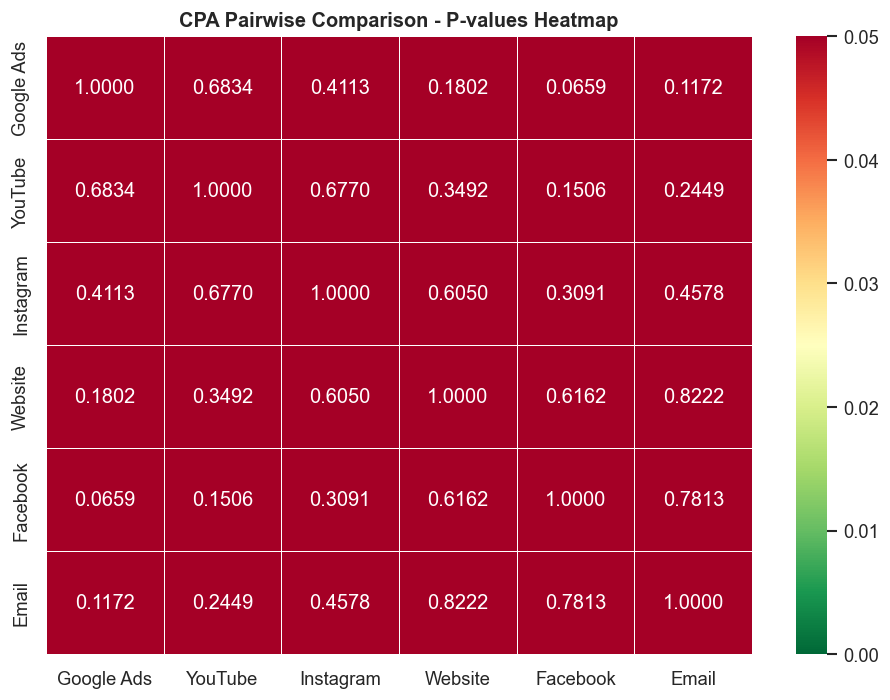

Saved: metric_comparison_heatmap.png


In [3]:
# CELL 3 - P-value heatmap
group_list = list(groups)
n = len(group_list)
matrix = pd.DataFrame(np.ones((n, n)), index=group_list, columns=group_list)

for _, row in ttest_df.iterrows():
    matrix.loc[row["group_a"], row["group_b"]] = row["p_value"]
    matrix.loc[row["group_b"], row["group_a"]] = row["p_value"]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(matrix, annot=True, fmt=".4f", cmap="RdYlGn_r",
            vmin=0, vmax=0.05, ax=ax, linewidths=0.5)
ax.set_title("CPA Pairwise Comparison - P-values Heatmap", fontweight="bold")
plt.tight_layout()
plt.savefig("lab_statistical_analysis/metric_comparison_heatmap.png", bbox_inches="tight")
plt.show()
print("Saved: metric_comparison_heatmap.png")

In [4]:
# CELL 4 - Fisher's exact test on conversion rates
conv_summary = df.groupby(grouping_col).agg(
    total_clicks  = ("Clicks", "sum"),
    total_conv    = ("Conversion_Rate", "sum")
).reset_index()

conv_summary["total_conv"]    = conv_summary["total_conv"].astype(int)
conv_summary["non_conv"]      = conv_summary["total_clicks"] - conv_summary["total_conv"]
conv_summary["rate"]          = conv_summary["total_conv"] / conv_summary["total_clicks"]

print("=== CONVERSION SUMMARY ===")
display(conv_summary)

results_fisher = []

for g1, g2 in pairs:
    r1 = conv_summary[conv_summary[grouping_col] == g1].iloc[0]
    r2 = conv_summary[conv_summary[grouping_col] == g2].iloc[0]

    table = [[r1["total_conv"], r1["non_conv"]],
             [r2["total_conv"], r2["non_conv"]]]

    odds_ratio, p_val = fisher_exact(table, alternative="two-sided")
    diff = r2["rate"] - r1["rate"]
    pct_diff = (diff / r1["rate"]) * 100 if r1["rate"] > 0 else np.nan

    results_fisher.append({
        "group_a": g1, "group_b": g2,
        "conv_a": r1["total_conv"], "conv_b": r2["total_conv"],
        "rate_a": round(r1["rate"], 6), "rate_b": round(r2["rate"], 6),
        "difference": round(diff, 6), "pct_difference": round(pct_diff, 4),
        "odds_ratio": round(odds_ratio, 4), "p_value": round(p_val, 6),
        "significant": p_val < 0.05
    })

fisher_df = pd.DataFrame(results_fisher)
print(f"\nTotal comparisons: {len(fisher_df)}")
print(f"Significant at p<0.05: {fisher_df['significant'].sum()}")
display(fisher_df)

=== CONVERSION SUMMARY ===


,Channel_Used,total_clicks,total_conv,non_conv,rate
0,Email,18493963,2697,18491266,0.000146
1,Facebook,18037947,2625,18035322,0.000146
2,Google Ads,18340807,2681,18338126,0.000146
3,Instagram,18316654,2667,18313987,0.000146
4,Website,18414628,2674,18411954,0.000145
5,YouTube,18350407,2667,18347740,0.000145



Total comparisons: 15
Significant at p<0.05: 0


,group_a,group_b,conv_a,conv_b,rate_a,rate_b,difference,pct_difference,odds_ratio,p_value,significant
0,Google Ads,YouTube,2681,2667,0.000146,0.000145,-0.000001,-0.5742,1.0058,0.837479,False
1,Google Ads,Instagram,2681,2667,0.000146,0.000146,-0.000001,-0.3910,1.0039,0.891231,False
2,Google Ads,Website,2681,2674,0.000146,0.000145,-0.000001,-0.6609,1.0067,0.816287,False
3,Google Ads,Facebook,2681,2625,0.000146,0.000146,-0.000001,-0.4448,1.0045,0.879956,False
4,Google Ads,Email,2681,2697,0.000146,0.000146,-0.000000,-0.2363,1.0024,0.934791,False
5,YouTube,Instagram,2667,2667,0.000145,0.000146,0.000000,0.1843,0.9982,0.956320,False
6,YouTube,Website,2667,2674,0.000145,0.000145,-0.000000,-0.0872,1.0009,0.978167,False
7,YouTube,Facebook,2667,2625,0.000145,0.000146,0.000000,0.1302,0.9987,0.967103,False
8,YouTube,Email,2667,2697,0.000145,0.000146,0.000000,0.3399,0.9966,0.902199,False
9,Instagram,Website,2667,2674,0.000146,0.000145,-0.000000,-0.2710,1.0027,0.923693,False


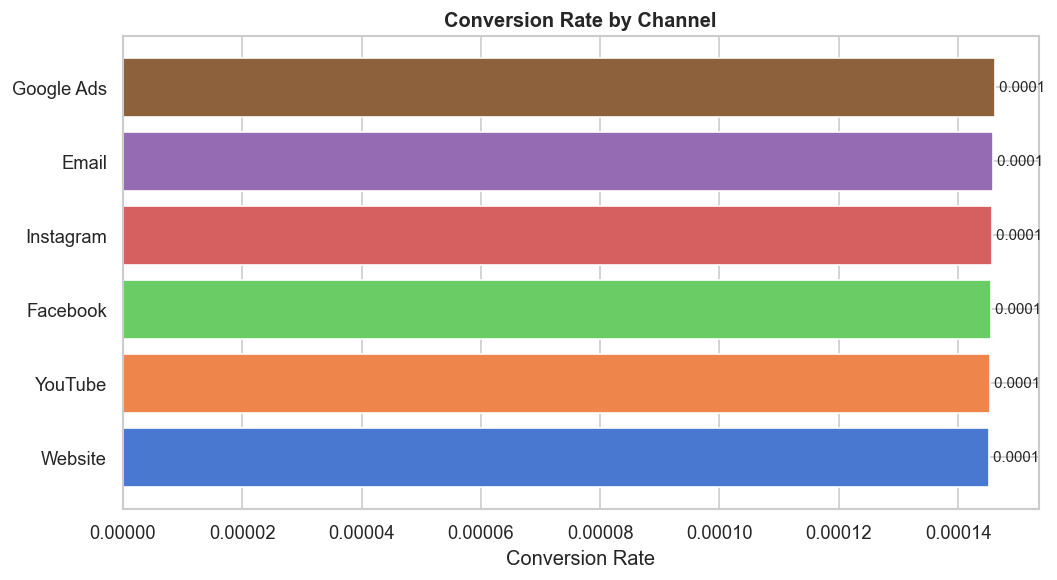

Saved: rate_comparison.png


In [5]:
# CELL 5 - Conversion rate bar chart
conv_sorted = conv_summary.sort_values("rate", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(conv_sorted[grouping_col], conv_sorted["rate"],
               color=sns.color_palette("muted", n_colors=len(conv_sorted)))
ax.set_title("Conversion Rate by Channel", fontweight="bold")
ax.set_xlabel("Conversion Rate")

for bar in bars:
    w = bar.get_width()
    ax.text(w, bar.get_y() + bar.get_height() / 2,
            f" {w:.4f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("lab_statistical_analysis/rate_comparison.png", bbox_inches="tight")
plt.show()
print("Saved: rate_comparison.png")

In [6]:
# CELL 6 - Multiple comparisons correction
n_ttest = len(ttest_df)
n_fisher = len(fisher_df)
n_total = n_ttest + n_fisher
alpha = 0.05

print("=== MULTIPLE COMPARISONS PROBLEM ===")
print(f"CPA comparisons: {n_ttest}")
print(f"Conversion rate comparisons: {n_fisher}")
print(f"Total comparisons: {n_total}")
print(f"Expected false positives by chance: {n_total * alpha:.1f}")

=== MULTIPLE COMPARISONS PROBLEM ===
CPA comparisons: 15
Conversion rate comparisons: 15
Total comparisons: 30
Expected false positives by chance: 1.5


In [7]:
# CELL 7 - Bonferroni correction
alpha_bonf_cpa    = alpha / n_ttest
alpha_bonf_fisher = alpha / n_fisher

ttest_df["significant_bonferroni"]  = ttest_df["p_value"]  < alpha_bonf_cpa
fisher_df["significant_bonferroni"] = fisher_df["p_value"] < alpha_bonf_fisher

print("=== BONFERRONI CORRECTION ===")
print(f"Adjusted alpha (CPA): {alpha_bonf_cpa:.6f}")
print(f"Adjusted alpha (conversion rate): {alpha_bonf_fisher:.6f}")
print(f"CPA significant after Bonferroni: {ttest_df['significant_bonferroni'].sum()}")
print(f"Conversion rate significant after Bonferroni: {fisher_df['significant_bonferroni'].sum()}")

=== BONFERRONI CORRECTION ===
Adjusted alpha (CPA): 0.003333
Adjusted alpha (conversion rate): 0.003333
CPA significant after Bonferroni: 0
Conversion rate significant after Bonferroni: 0


In [8]:
# CELL 8 - FDR Benjamini-Hochberg correction
ttest_df["p_value_fdr"]  = false_discovery_control(ttest_df["p_value"].values,  method="bh")
fisher_df["p_value_fdr"] = false_discovery_control(fisher_df["p_value"].values, method="bh")

ttest_df["significant_fdr"]  = ttest_df["p_value_fdr"]  < alpha
fisher_df["significant_fdr"] = fisher_df["p_value_fdr"] < alpha

print("=== FDR BENJAMINI-HOCHBERG CORRECTION ===")
print(f"CPA significant after FDR: {ttest_df['significant_fdr'].sum()}")
print(f"Conversion rate significant after FDR: {fisher_df['significant_fdr'].sum()}")

print("\nCPA comparisons remaining significant:")
display(ttest_df[ttest_df["significant_fdr"]])

print("\nConversion rate comparisons remaining significant:")
display(fisher_df[fisher_df["significant_fdr"]])

=== FDR BENJAMINI-HOCHBERG CORRECTION ===
CPA significant after FDR: 0
Conversion rate significant after FDR: 0

CPA comparisons remaining significant:


,group_a,group_b,mean_a,mean_b,difference,pct_difference,t_stat,p_value,cohens_d,effect_size,significant,significant_bonferroni,p_value_fdr,significant_fdr



Conversion rate comparisons remaining significant:


,group_a,group_b,conv_a,conv_b,rate_a,rate_b,difference,pct_difference,odds_ratio,p_value,significant,significant_bonferroni,p_value_fdr,significant_fdr


=== CORRECTION METHODS SUMMARY ===


,Method,CPA_significant,ConvRate_significant
0,Uncorrected (p<0.05),0,0
1,Bonferroni,0,0
2,FDR (BH),0,0


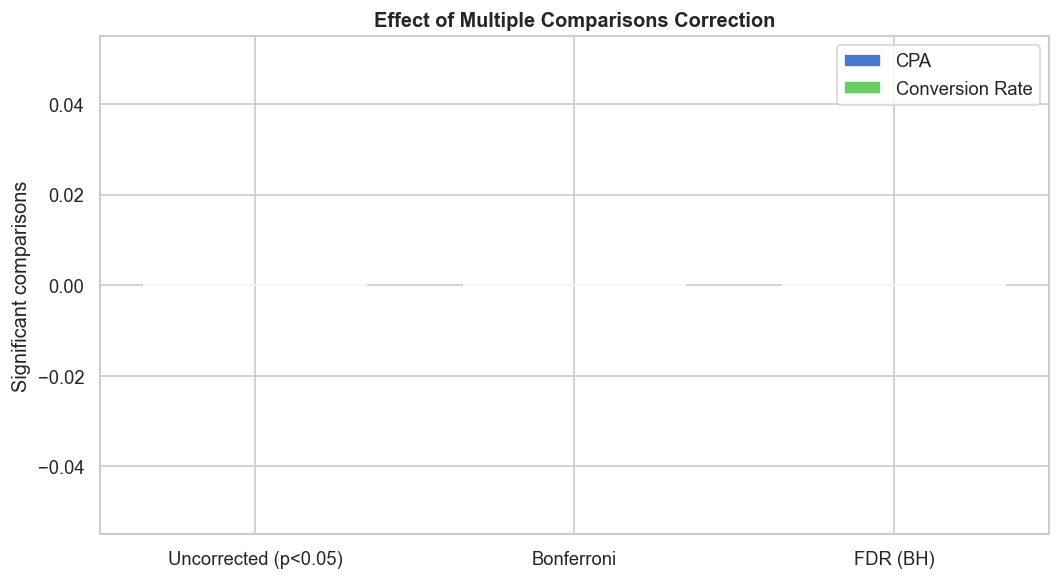

Saved: correction_comparison.png


In [9]:
# CELL 9 - Correction methods comparison chart
summary = {
    "Method": ["Uncorrected (p<0.05)", "Bonferroni", "FDR (BH)"],
    "CPA_significant": [
        ttest_df["significant"].sum(),
        ttest_df["significant_bonferroni"].sum(),
        ttest_df["significant_fdr"].sum()
    ],
    "ConvRate_significant": [
        fisher_df["significant"].sum(),
        fisher_df["significant_bonferroni"].sum(),
        fisher_df["significant_fdr"].sum()
    ]
}
summary_df = pd.DataFrame(summary)
print("=== CORRECTION METHODS SUMMARY ===")
display(summary_df)

x = np.arange(len(summary_df))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, summary_df["CPA_significant"],        width, label="CPA",             color="#4878cf")
ax.bar(x + width/2, summary_df["ConvRate_significant"],   width, label="Conversion Rate", color="#6acc65")
ax.set_xticks(x)
ax.set_xticklabels(summary_df["Method"])
ax.set_ylabel("Significant comparisons")
ax.set_title("Effect of Multiple Comparisons Correction", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("lab_statistical_analysis/correction_comparison.png", bbox_inches="tight")
plt.show()
print("Saved: correction_comparison.png")

In [10]:
# CELL 10 - Empirical power function
def empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05):
    rejections = 0
    for _ in range(n_sim):
        std = base_cpa * 0.15
        a = np.random.normal(base_cpa, std, n_days)
        a = np.clip(a, base_cpa * 0.5, np.inf)
        b = np.random.normal(base_cpa * (1 + true_diff_pct), std, n_days)
        b = np.clip(b, base_cpa * 0.5, np.inf)
        _, p = ttest_ind(a, b)
        if p < alpha:
            rejections += 1
    return rejections / n_sim

base_cpa = df["CPA_row"].dropna().mean()
effect_sizes = [0.05, 0.10, 0.15, 0.20]
sample_sizes = [30, 60, 90, 120, 180]

print(f"Base CPA: {base_cpa:.2f}")
print("Running power simulations...")

power_results = []
for eff in effect_sizes:
    for n in sample_sizes:
        power = empirical_power_cpa(eff, base_cpa, n, n_sim=1000)
        power_results.append({
            "effect_size_pct": int(eff * 100),
            "n_days": n,
            "power": round(power, 3)
        })

power_df = pd.DataFrame(power_results)
print("Done.")

Base CPA: 248199.46
Running power simulations...
Done.


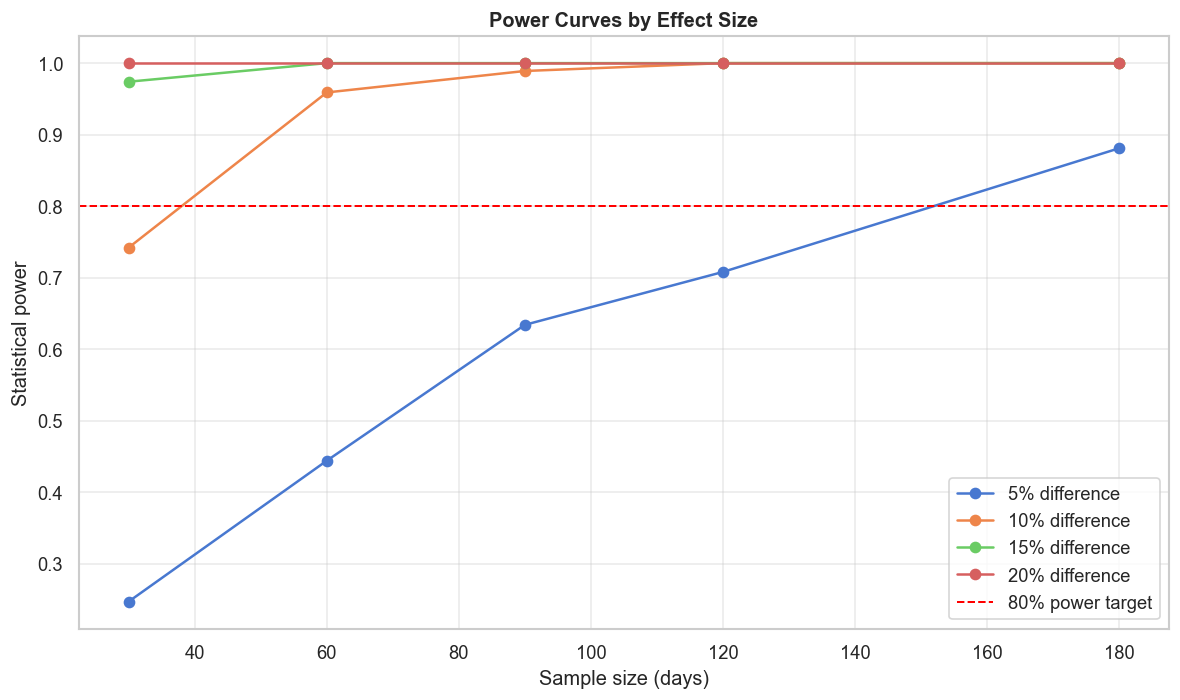

Saved: power_analysis_cpa.png

=== POWER TABLE ===


effect_size_pct,5,10,15,20
n_days,,,,
30,0.247,0.742,0.974,1.0
60,0.444,0.959,1.000,1.0
90,0.634,0.989,1.000,1.0
120,0.708,1.000,1.000,1.0
180,0.881,1.000,1.000,1.0


In [11]:
# CELL 11 - Power curves
fig, ax = plt.subplots(figsize=(10, 6))

for eff in [5, 10, 15, 20]:
    subset = power_df[power_df["effect_size_pct"] == eff]
    ax.plot(subset["n_days"], subset["power"], marker="o", label=f"{eff}% difference")

ax.axhline(0.80, color="red", linestyle="--", linewidth=1.2, label="80% power target")
ax.set_xlabel("Sample size (days)")
ax.set_ylabel("Statistical power")
ax.set_title("Power Curves by Effect Size", fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("lab_statistical_analysis/power_analysis_cpa.png", bbox_inches="tight")
plt.show()
print("Saved: power_analysis_cpa.png")

print("\n=== POWER TABLE ===")
display(power_df.pivot(index="n_days", columns="effect_size_pct", values="power"))

In [12]:
# CELL 12 - Minimum sample size for 80% power
print("=== MINIMUM DAYS FOR 80% POWER ===")
print(f"{'Effect Size':<15} {'Min Days':<12} {'Status (90 days)'}")
print("-" * 45)

for eff in [5, 10, 15, 20]:
    subset = power_df[power_df["effect_size_pct"] == eff].sort_values("n_days")
    sufficient = subset[subset["power"] >= 0.80]
    if len(sufficient) > 0:
        min_days = sufficient.iloc[0]["n_days"]
        status = "Sufficient" if min_days <= 90 else "Insufficient"
    else:
        min_days = ">180"
        status = "Insufficient"
    print(f"{str(eff)+'%':<15} {str(min_days):<12} {status}")

=== MINIMUM DAYS FOR 80% POWER ===
Effect Size     Min Days     Status (90 days)
---------------------------------------------
5%              180.0        Insufficient
10%             60.0         Sufficient
15%             30.0         Sufficient
20%             30.0         Sufficient


In [13]:
# CELL 13 - Current data adequacy
print("=== CURRENT DATA ADEQUACY ASSESSMENT ===")
print("No pairs survived FDR correction, so no specific pairs to assess.")
print("General assessment based on observed CPA variability:\n")

for eff in [5, 10, 15, 20]:
    subset = power_df[power_df["effect_size_pct"] == eff]
    power_90 = subset[subset["n_days"] == 90]["power"].values
    if len(power_90) > 0:
        print(f"{eff}% difference -> Power at 90 days: {power_90[0]:.1%}")

=== CURRENT DATA ADEQUACY ASSESSMENT ===
No pairs survived FDR correction, so no specific pairs to assess.
General assessment based on observed CPA variability:

5% difference -> Power at 90 days: 63.4%
10% difference -> Power at 90 days: 98.9%
15% difference -> Power at 90 days: 100.0%
20% difference -> Power at 90 days: 100.0%
